# Interpreting results

<!-- markdownlint-disable MD033-->
<div class="page-subtitle">
Visualising and interpreting a change map
</div>
<!-- markdownlint-enable MD033 -->

---

You ran ChangeStar on the Osaka image pair on the previous page. This page works through exactly what `result` contains and how to look at it critically, before the next page covers thresholds, model variants and export.

---

## 1. Motivation

`result` is not just a change map; it is a small bundle of related rasters that, read together, tell you much more than any single one alone. Learning to read all of them is what lets you judge whether a detected change is trustworthy, rather than accepting a binary mask at face value. Without reference data, this critical reading is often the only quality check you have.

---

## 2. Core idea

ChangeStar's `predict()` returns the binary change map, the underlying change probability, and both hard and probabilistic building masks for each of the two dates. Three habits turn these outputs into an interpretation:

1. **Read the probabilities, not only the binary maps.** A {term}`probability map <Probability Map>` shows how confident each decision was.
2. **Combine the two building masks into a "from–to" map.** It tells you *what kind* of change happened (new building or removed building), not only *that* something changed.
3. **Check surprising detections against the images.** Every model makes errors; zooming in on a few locations reveals what kinds of errors this one makes.

---

## 3. Workflow

### A. Reload the result

In [1]:
import logging
import os
import warnings
from pathlib import Path

os.environ["HF_HUB_VERBOSITY"] = "error"
warnings.filterwarnings("ignore")
for name in ["httpx", "huggingface_hub", "pyogrio", "numexpr", "rasterio"]:
    logging.getLogger(name).setLevel(logging.ERROR)

import geoai
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy import ndimage
from geoai.change_detection import ChangeStarDetection

RGB_DIR = Path("data/processed")
OUT_DIR = Path("changestar_results")
rgb_paths = {year: RGB_DIR / f"vexcel_osaka_{year}_rgb.tif" for year in [2022, 2025]}
PIXEL_AREA_M2 = 0.2 * 0.2

device = geoai.get_device()
detector = ChangeStarDetection(model_name="s1_s1c1_vitb", device=device)

cache = OUT_DIR / "changestar_s1_result.npz"
if cache.exists():
    result = dict(np.load(cache))
    print(f"Loaded saved result from {cache}")
else:
    print("No saved result found: run the previous page first (it downloads and prepares the images).")

2026-11-15 21:28:08, INFO:EVER:Load Changen2 pre-trained weight from EVER-Z/Changen2-ChangeStar1x256/s1c1_cstar_vitb_1x256.pth


2026-11-15 21:28:08, INFO:EVER:architecture: changestar_1x256 | backbone: vitb | modeling type: s1c1 | pre-trained data: Changen2-S1-15k | finetuned on: None


Loaded saved result from changestar_results/changestar_s1_result.npz


The previous page saved its full result to disk, so we load it instead of running the model again. Creating `detector` loads the model weights (a few seconds, already downloaded on the previous page), but on this page we only use its plotting functions.

### B. What `result` contains

In [2]:
for key, value in result.items():
    print(f"{key:18s} shape={value.shape}, dtype={value.dtype}, range {value.min():.2f} to {value.max():.2f}")

change_map         shape=(1500, 3000), dtype=uint8, range 0.00 to 1.00
change_prob        shape=(1500, 3000), dtype=float32, range 0.00 to 1.00
t1_semantic        shape=(1500, 3000), dtype=uint8, range 0.00 to 1.00
t2_semantic        shape=(1500, 3000), dtype=uint8, range 0.00 to 1.00
t1_semantic_prob   shape=(1500, 3000), dtype=float32, range 0.00 to 1.00
t2_semantic_prob   shape=(1500, 3000), dtype=float32, range 0.00 to 1.00


| Key | Type | Content |
| --- | --- | --- |
| `change_map` | Binary raster (`uint8`) | 1 = changed, 0 = unchanged; the change probability above the threshold of 0.5 |
| `change_prob` | Probability raster (`float32`) | Per-pixel probability of change, 0 to 1 |
| `t1_semantic`, `t2_semantic` | Binary rasters (`uint8`) | Building masks for 2022 (T1) and 2025 (T2) |
| `t1_semantic_prob`, `t2_semantic_prob` | Probability rasters (`float32`) | Per-pixel building probability for each date |

All six arrays share the same 1500 × 3000 pixel grid as the input images, so the same pixel position always refers to the same place on the ground. (When you call `predict()` directly, the dictionary also contains `num_semantic_classes`, the number of segmentation classes; for this variant it is 1, building.)

### C. The overview

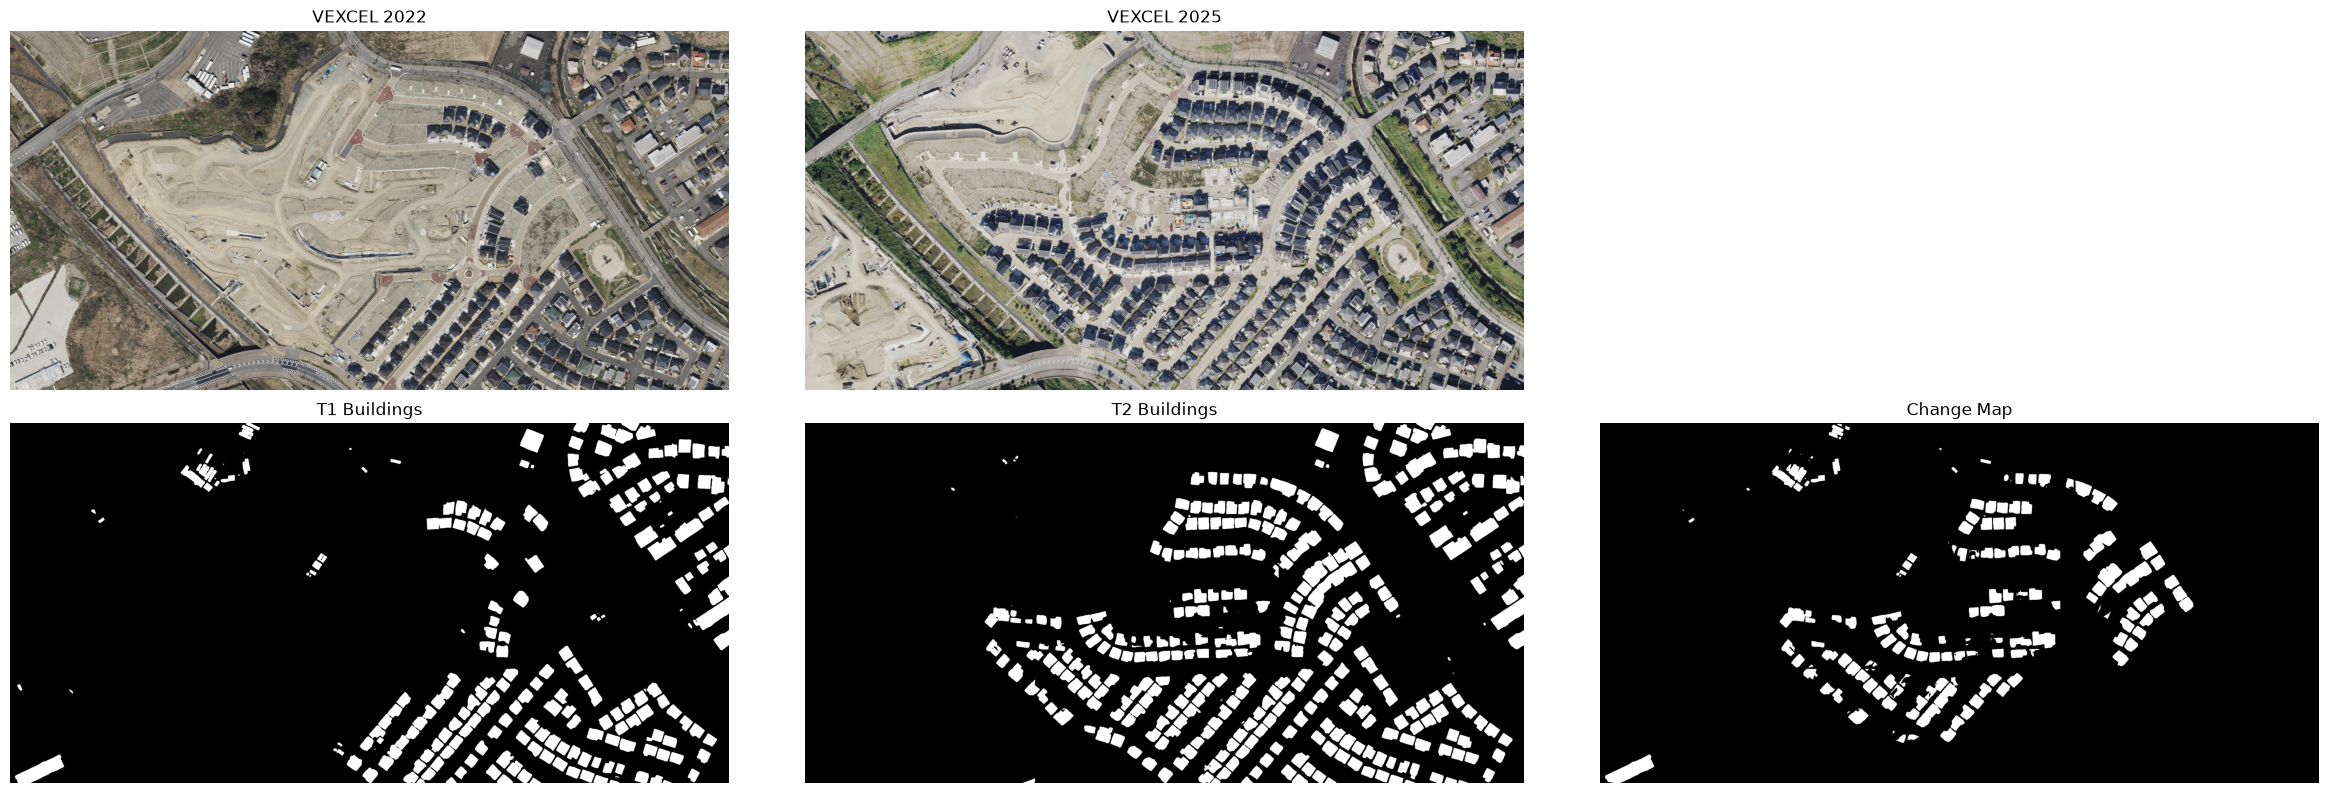

In [3]:
fig = detector.visualize(
    str(rgb_paths[2022]),
    str(rgb_paths[2025]),
    result=result,
    figsize=(24, 8),
    title1="VEXCEL 2022",
    title2="VEXCEL 2025",
)
plt.show()

`visualize()` lays out the before image, the after image, the building mask for each date and the change map. Comparing the two building masks by eye already explains most of the change map: the new rows of houses in the centre exist only in the 2025 mask. Also note what is *not* there: the established neighbourhood along the right and bottom edges is segmented consistently at both dates, so it produces no change.

### D. Overlay on the imagery

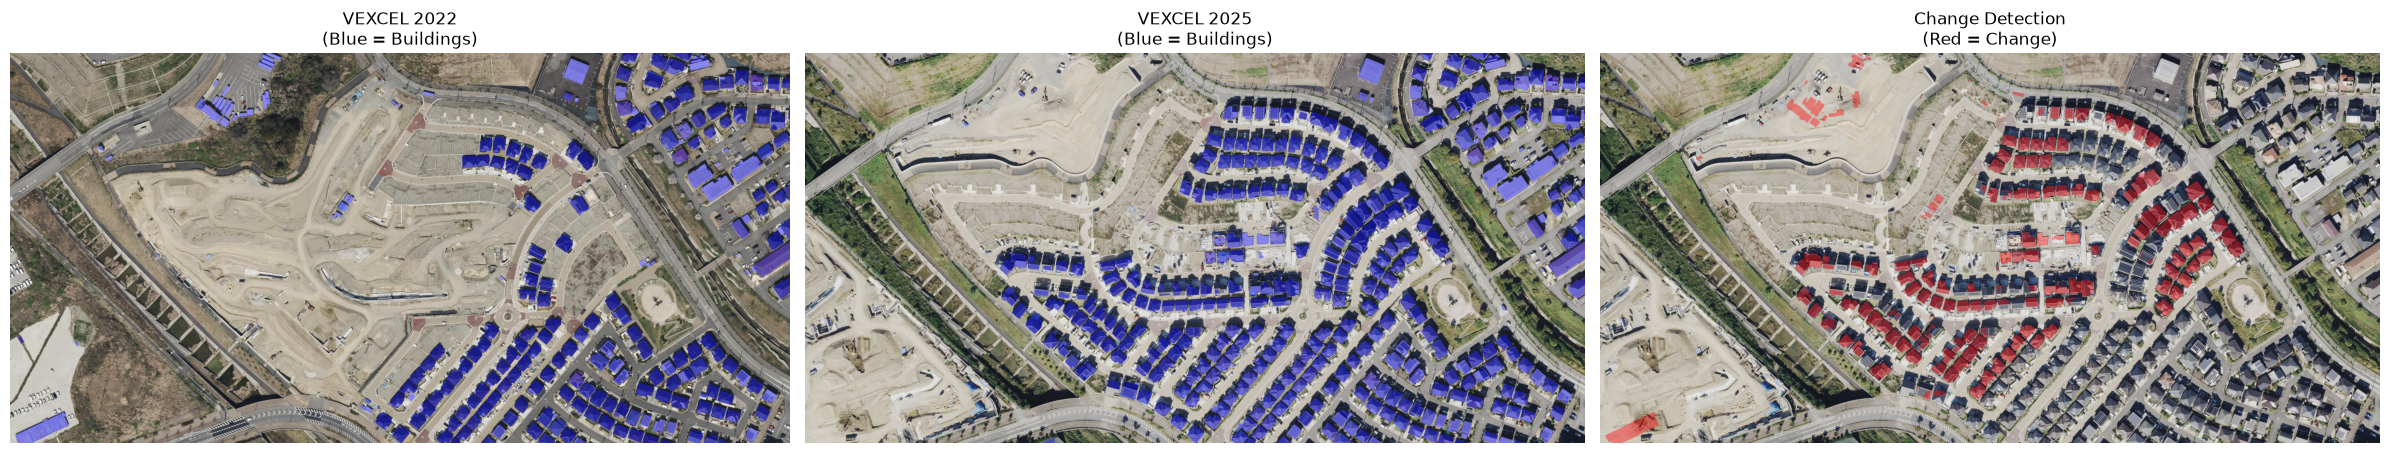

In [4]:
fig = detector.visualize_overlay(
    str(rgb_paths[2022]),
    str(rgb_paths[2025]),
    result=result,
    figsize=(24, 4.5),
    title1="VEXCEL 2022",
    title2="VEXCEL 2025",
)
plt.show()

`visualize_overlay()` draws detected buildings (blue) and detected changes (red) directly on the imagery. This makes plausibility checks quicker: does every red patch sit on something that visibly changed? Look closely at the car park in the upper left of the 2022 image: some of the parked buses and trucks are drawn in blue, as if they were buildings. Step G returns to this.

### E. Reading the probability map

Confidently unchanged (p < 0.3)   93.3% of pixels
Uncertain (0.3 to 0.7)             1.5% of pixels
Confidently changed (p > 0.7)      5.2% of pixels
Uncertain pixels at the edge of a detected change: 63%


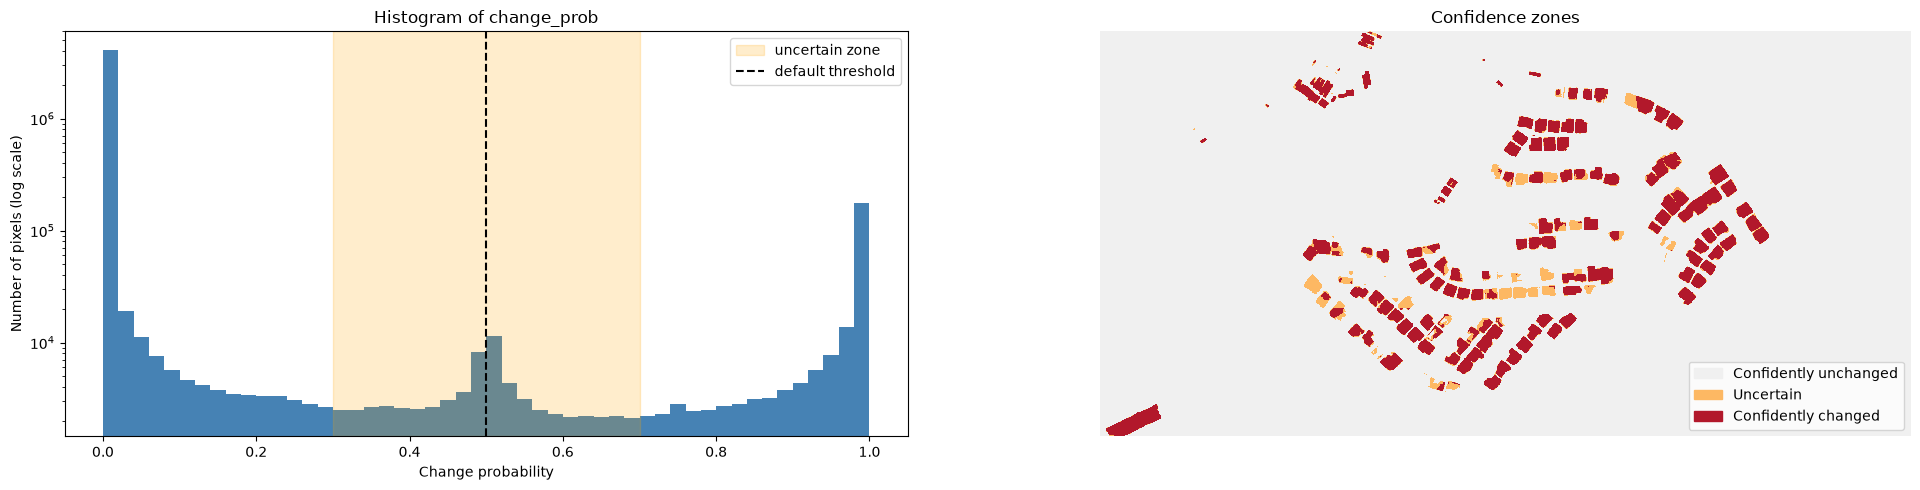

In [5]:
prob = result["change_prob"]
confident_unchanged = prob < 0.3
uncertain = (prob >= 0.3) & (prob <= 0.7)
confident_changed = prob > 0.7

for name, mask in [
    ("Confidently unchanged (p < 0.3)", confident_unchanged),
    ("Uncertain (0.3 to 0.7)", uncertain),
    ("Confidently changed (p > 0.7)", confident_changed),
]:
    print(f"{name:32s} {100 * mask.mean():5.1f}% of pixels")

# How many uncertain pixels lie at the edge of a detected change (within 3 px = 0.6 m)?
edge = ndimage.binary_dilation(result["change_map"], iterations=3) & ~ndimage.binary_erosion(
    result["change_map"], iterations=3
)
print(f"Uncertain pixels at the edge of a detected change: {100 * (uncertain & edge).sum() / uncertain.sum():.0f}%")

zones = np.zeros(prob.shape, dtype=np.uint8)
zones[uncertain] = 1
zones[confident_changed] = 2
zone_colours = ["#f0f0f0", "#fdb863", "#b2182b"]
zone_names = ["Confidently unchanged", "Uncertain", "Confidently changed"]

fig, axes = plt.subplots(1, 2, figsize=(22, 5), gridspec_kw={"width_ratios": [1, 1.6]})
axes[0].hist(prob.ravel(), bins=50, range=(0, 1), color="steelblue", log=True)
axes[0].axvspan(0.3, 0.7, color="orange", alpha=0.2, label="uncertain zone")
axes[0].axvline(0.5, color="black", linestyle="--", label="default threshold")
axes[0].set_xlabel("Change probability")
axes[0].set_ylabel("Number of pixels (log scale)")
axes[0].set_title("Histogram of change_prob")
axes[0].legend()

axes[1].imshow(zones, cmap=ListedColormap(zone_colours), vmin=0, vmax=2, interpolation="nearest")
axes[1].set_title("Confidence zones")
axes[1].axis("off")
axes[1].legend(handles=[Patch(color=c, label=n) for c, n in zip(zone_colours, zone_names)], loc="lower right")
plt.tight_layout()
plt.show()

The histogram uses a logarithmic y-axis; on a normal axis, the huge peak near 0 would hide everything else. The model is decisive for most pixels: almost all probabilities sit close to 0 or close to 1, and only a small share falls in between. Where do the uncertain pixels lie? The map shows two patterns. About two thirds form thin rims around detected changes: the model is sure *that* a house appeared, but less sure exactly where its outline runs, because roof edges, eaves and shadows blur the boundary. The rest cover whole houses or parts of houses that the model is unsure about as a whole. These are the places worth inspecting, because a slightly different threshold would flip them between "changed" and "unchanged".

The histogram also shows a small, sharp peak at exactly 0.5. It is an artefact of {term}`tiled inference <Tiled Inference>`: the scene is processed in overlapping tiles of 1024 × 1024 pixels, and where tiles overlap their probabilities are averaged. If one tile says "certainly changed" (close to 1) and the overlapping tile says "certainly unchanged" (close to 0), the average lands near 0.5. The two tiles saw the same pixel with different surroundings and reached different decisions.

```{admonition} A changed pixel with low confidence is a different situation than one with high confidence
:class: note
`change_map` gives a firm yes/no per pixel, but `change_prob` tells you how confident that decision was. Two pixels can both appear as "changed" while one had a probability of 0.99 and the other 0.51. Before treating a detected change area as reliable, especially a small or unusual-looking one, check its probability values.
```

### F. From "changed" to "from–to"

The change map says *that* something changed. The two building masks say *what* was there at each date. Combining them gives a small categorical change map, a simple form of {term}`post-classification comparison <Post-Classification Comparison>`:

| 2022 mask | 2025 mask | Category |
| --- | --- | --- |
| no building | no building | No building |
| building | building | Unchanged building |
| no building | building | New building |
| building | no building | Removed building |

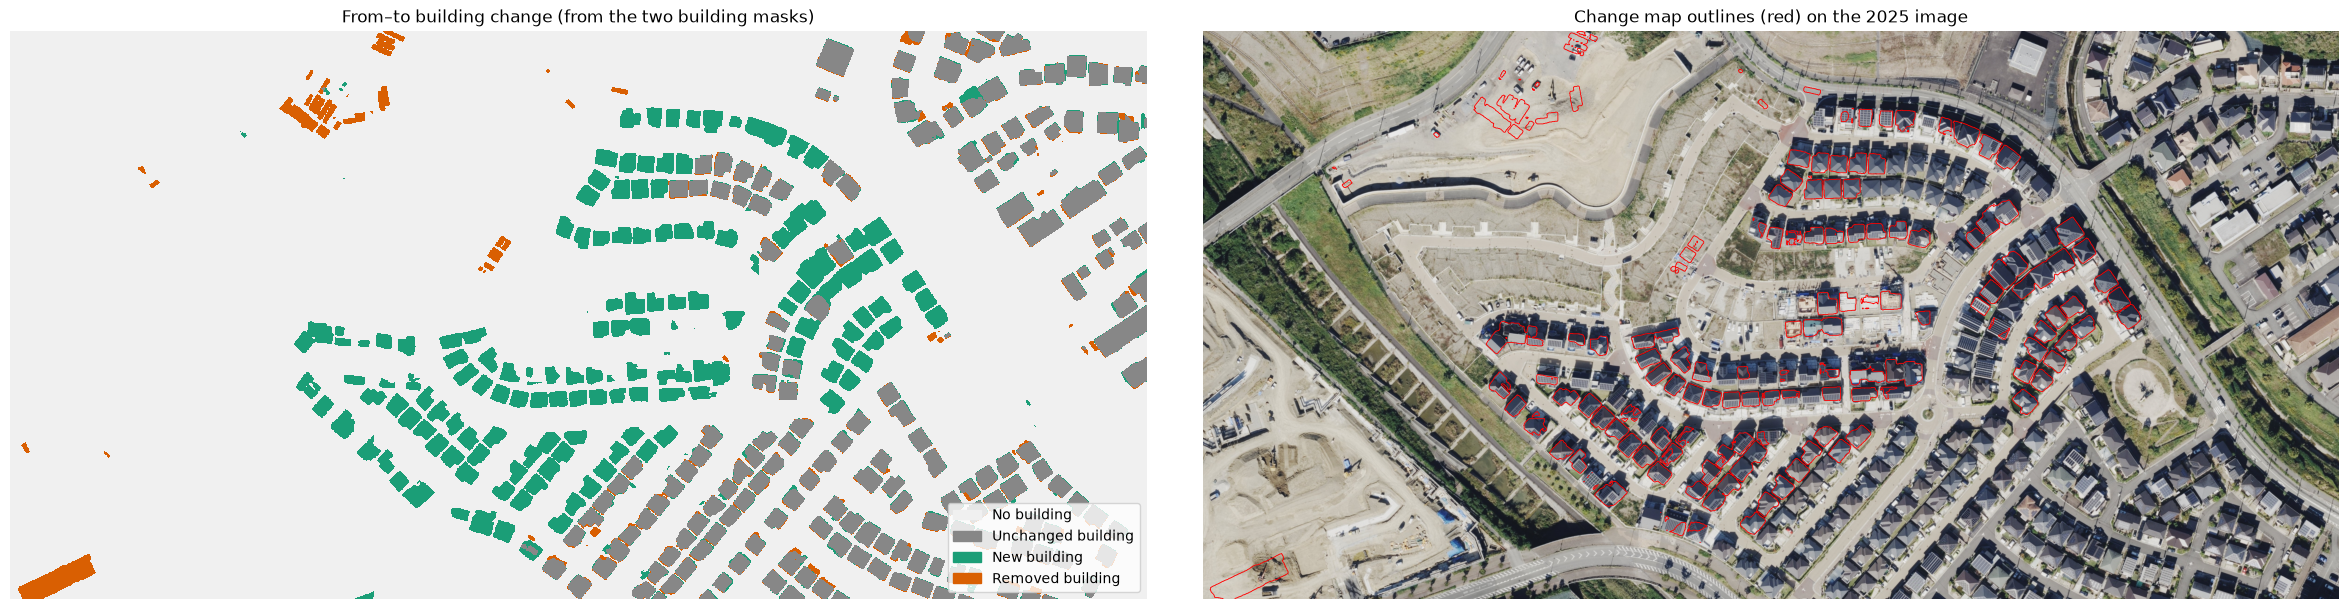

,area_m2,share_flagged_as_change
No building,149413.16,0.00
Unchanged building,15335.56,0.00
New building,13062.80,0.73
Removed building,2188.48,0.50


In [6]:
t1, t2 = result["t1_semantic"], result["t2_semantic"]
from_to = np.zeros(t1.shape, dtype=np.uint8)
from_to[(t1 == 1) & (t2 == 1)] = 1  # unchanged building
from_to[(t1 == 0) & (t2 == 1)] = 2  # new building
from_to[(t1 == 1) & (t2 == 0)] = 3  # removed building

ft_names = ["No building", "Unchanged building", "New building", "Removed building"]
ft_colours = ["#f0f0f0", "#878787", "#1b9e77", "#d95f02"]

with rasterio.open(rgb_paths[2025]) as src:
    img_2025 = np.moveaxis(src.read(), 0, -1)

fig, axes = plt.subplots(1, 2, figsize=(24, 6))
axes[0].imshow(from_to, cmap=ListedColormap(ft_colours), vmin=0, vmax=3, interpolation="nearest")
axes[0].set_title("From–to building change (from the two building masks)")
axes[1].imshow(img_2025)
axes[1].contour(result["change_map"], levels=[0.5], colors="red", linewidths=0.6)
axes[1].set_title("Change map outlines (red) on the 2025 image")
for ax in axes:
    ax.axis("off")
axes[0].legend(handles=[Patch(color=c, label=n) for c, n in zip(ft_colours, ft_names)], loc="lower right")
plt.tight_layout()
plt.show()

summary = pd.DataFrame(
    {
        "area_m2": [np.sum(from_to == v) * PIXEL_AREA_M2 for v in range(4)],
        "share_flagged_as_change": [result["change_map"][from_to == v].mean() for v in range(4)],
    },
    index=ft_names,
).round(2)
summary

The table connects the two kinds of output. Almost nothing outside new or removed buildings is flagged as change: ChangeStar's change map is closely tied to its own building segmentation, which is what you would expect from a model trained on building change. But the link is not perfect. Roughly a quarter of the "new building" area is *not* flagged in the change map, and about half of the "removed building" area is not either. Where the two outputs disagree, the model is effectively disagreeing with itself, and those are exactly the places to inspect next.

The from–to map also answers a question the binary change map cannot: it separates construction (new buildings) from demolition (removed buildings). This is the step from a binary towards a categorical change product discussed on the first page of this lesson.

### G. Inspect individual locations

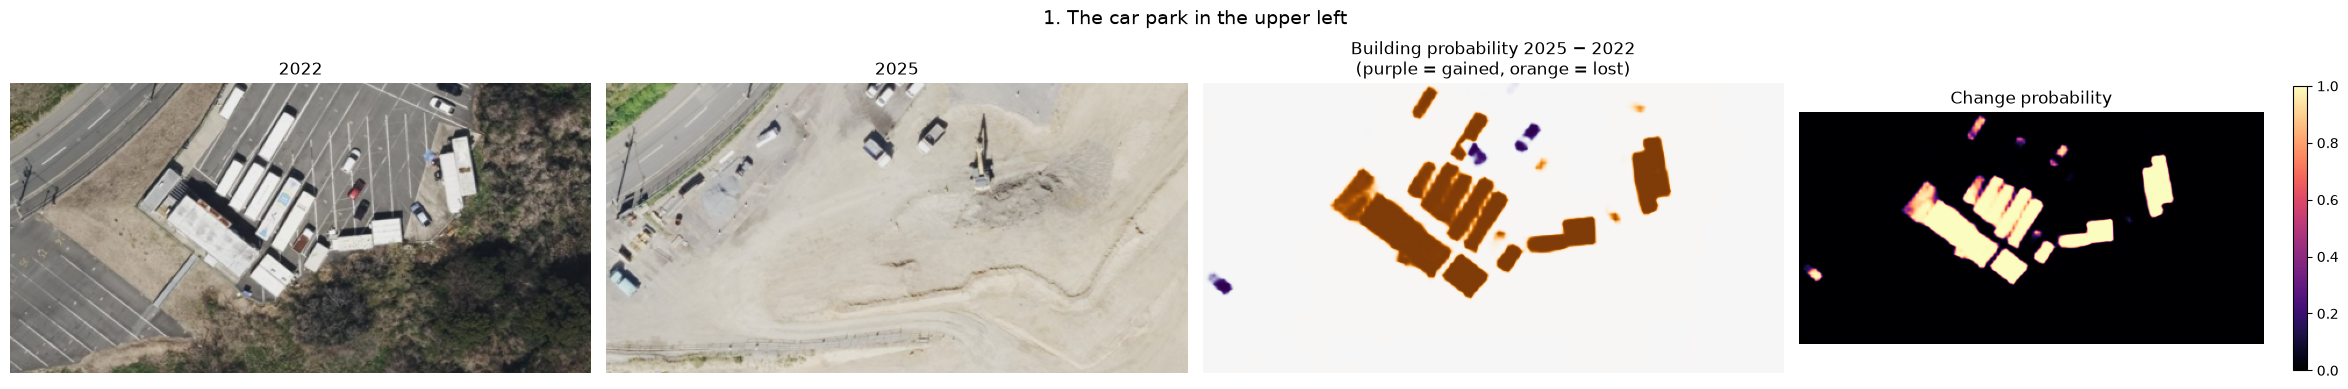

In [7]:
with rasterio.open(rgb_paths[2022]) as src:
    img_2022 = np.moveaxis(src.read(), 0, -1)

def inspect(rows, cols, title):
    """Show both dates, the building probability change and the change probability for one window."""
    fig, axes = plt.subplots(1, 4, figsize=(24, 4.2))
    axes[0].imshow(img_2022[rows, cols])
    axes[0].set_title("2022")
    axes[1].imshow(img_2025[rows, cols])
    axes[1].set_title("2025")
    diff = result["t2_semantic_prob"][rows, cols] - result["t1_semantic_prob"][rows, cols]
    axes[2].imshow(diff, cmap="PuOr", vmin=-1, vmax=1)
    axes[2].set_title("Building probability 2025 − 2022\n(purple = gained, orange = lost)")
    im = axes[3].imshow(result["change_prob"][rows, cols], cmap="magma", vmin=0, vmax=1)
    axes[3].set_title("Change probability")
    fig.colorbar(im, ax=axes[3], shrink=0.8)
    for ax in axes:
        ax.axis("off")
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

inspect(slice(100, 350), slice(600, 1100), "1. The car park in the upper left")

**Location 1, a false alarm.** In 2022, buses and trucks were parked here; in 2025, the car park has been replaced by earthworks. The model segmented several of the large vehicles as buildings in 2022, so their disappearance looks like *removed buildings*, with change probabilities close to 1. From above, a long bus roof does resemble a small flat-roofed building. A confident probability is therefore no guarantee of a correct detection: the model was confident about the wrong thing.

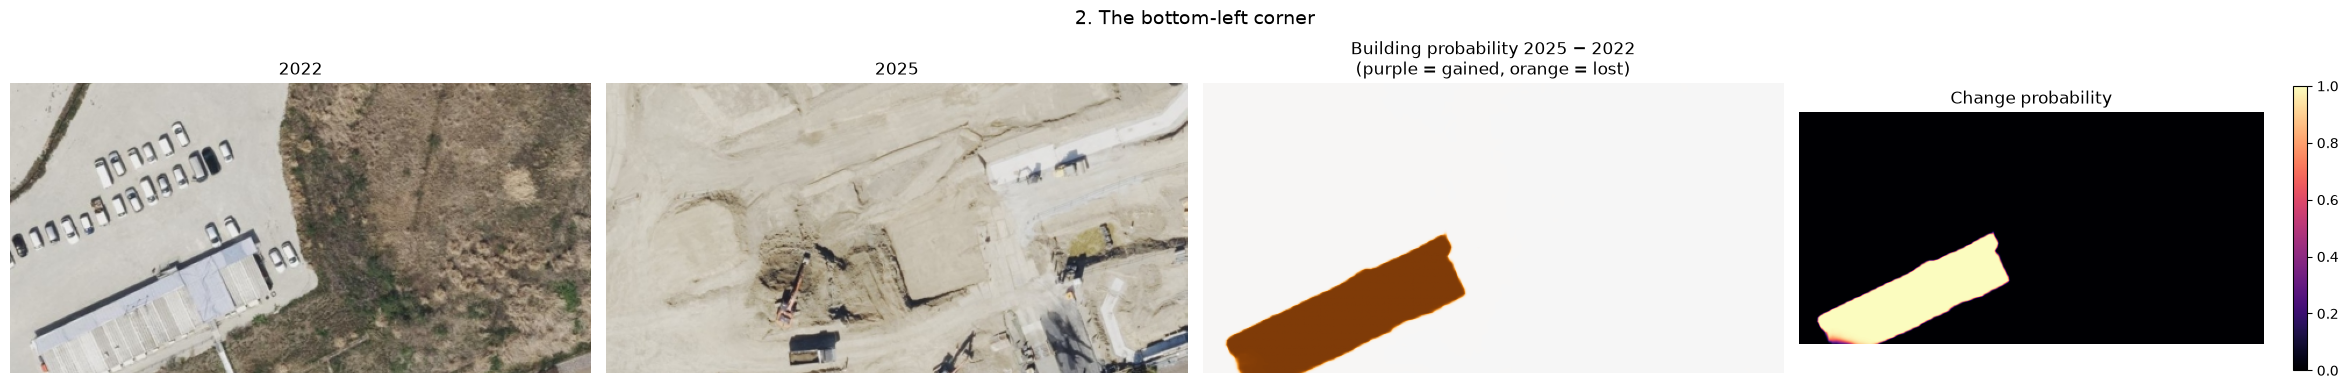

In [8]:
inspect(slice(1250, 1500), slice(0, 500), "2. The bottom-left corner")

**Location 2, a correct detection of loss.** A large building present in 2022 has been demolished, and the site is being dug up in 2025. Both building probability and change probability agree, and the from–to map correctly labels this as a removed building. Note that a project counting "new construction" would need to exclude this kind of change: the binary change map alone does not tell the two apart.

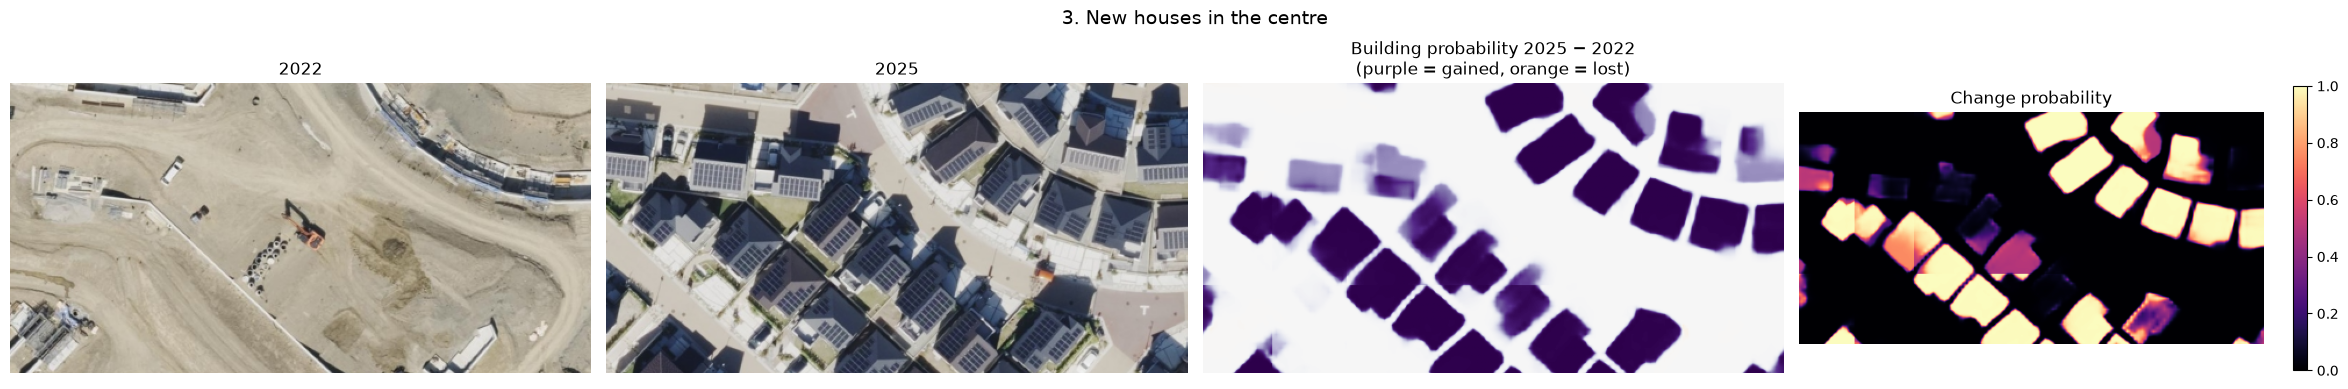

In [9]:
inspect(slice(850, 1100), slice(900, 1400), "3. New houses in the centre")

**Location 3, partial misses.** All of these houses are new: the 2022 image shows bare construction terraces. The building probability increases clearly for every house, but the change probability does not: some houses reach values close to 1, others only medium values (purple) and remain below the 0.5 threshold. These are the "new building" areas not flagged in step F; the model's change and segmentation outputs have weighed the evidence differently. Look closely at the change probability, too: some houses are cut by a perfectly straight line, with a different probability on either side. Houses have no straight seams, but tiles do. This window lies on the border between two processing tiles, and each tile reached a different decision for the same house. Lowering the threshold would recover some of the missed houses, at the risk of adding false alarms elsewhere, which is the trade-off explored on the next page.

---

## 4. Python reactivation

- `dict(np.load(cache))` loads all arrays from a `.npz` file into an ordinary dictionary, with the same keys used when saving.
- Boolean masks such as `(t1 == 0) & (t2 == 1)` combine conditions per pixel; `&` means "and". Each condition needs its own parentheses.
- `result["change_map"][from_to == v].mean()` uses one array to select pixels in another: the mean of a 0/1 array is the share of ones, here the share of an area flagged as changed.
- `slice(100, 350)` stores a row or column range in a variable, so the same window can be passed to `inspect()` and applied to several arrays.
- `ax.contour(mask, levels=[0.5])` draws the outline of a binary mask, which keeps the image underneath visible.

---

## 5. Common pitfalls

- **Trusting `change_map` without checking `change_prob`.** A binary mask hides exactly the confidence information that tells you which detections deserve scrutiny.
- **Treating high confidence as correctness.** The buses in location 1 were flagged with probabilities close to 1, and were still wrong.
- **Confusing T1 and T2.** T1 is always the earlier date; mixing them up turns new buildings into removed ones.
- **Reporting all change as "new construction".** The binary change map mixes gains and losses; the from–to map separates them.
- **Interpreting an isolated changed patch the same way as a large, coherent change area.** Small patches, especially away from buildings, are worth checking against the imagery before they are counted.
- **Mistaking processing artefacts for patterns on the ground.** Straight edges in a probability map, especially at regular intervals, usually come from tile boundaries, not from the landscape.
- **Ignoring the segmentation outputs when a change looks surprising.** If a building mask looks wrong at a location, an apparent change there may be a segmentation error rather than a real surface change.

---

## 6. Mini task

Pick one more location in the scene where you suspect a problem: for example a flagged patch away from the new houses, or a new house you think is missing in the change map. Use `inspect()` with your own row and column ranges. Using the outputs described on this page, decide whether it is a correct detection, a false alarm, or a miss, and name the evidence you used.

:::{dropdown} Sample solution
:class: note

One possible example is the small group of flagged pixels in the upper right of the car park, around rows 0–70 and columns 950–1050:

```python
inspect(slice(0, 120), slice(900, 1150), "Upper edge of the car park")
```

The 2022 image shows parked vehicles, the 2025 image an empty, levelled surface. The building probability drops from high to low (orange), and the change probability is high, so the model reports a removed building. Since the objects were vehicles, not buildings, this is a false alarm of the same kind as location 1. The evidence: (1) the imagery at both dates, (2) the building probability per date, which shows *why* the model flagged a change, and (3) the change probability, which shows how confident it was. Any location you choose can be judged in the same way, and noting whether a flagged change is a gain or a loss (from the from–to map) helps you decide whether it matters for your question.
:::

---

## 7. Key takeaways

- `result` bundles a binary change map and its probability, plus a hard and a probabilistic building mask for each date.
- `visualize()` gives a full overview; `visualize_overlay()` draws detections on the imagery for a quick plausibility check.
- Most change probabilities are close to 0 or 1; the uncertain pixels mostly outline detected changes, and uncertain whole houses are worth checking.
- Tiled inference leaves traces: straight seams and a peak at 0.5 in the probabilities show where overlapping tiles disagreed.
- Combining the two building masks gives a from–to map that separates new from removed buildings, a step towards categorical change.
- Inspecting individual locations reveals the model's typical errors, such as vehicles mistaken for buildings or new houses with only medium change probability; high confidence does not guarantee correctness.

### Further reading

- OpenGeoAI, ["ChangeStar"](https://opengeoai.org/examples/changestar/) — the example notebook with the `visualize()` and `visualize_overlay()` functions used here.
- Esri, ["Multi-Class Change Detection Using Segmentation Deep Learning Models"](https://developers.arcgis.com/python/latest/samples/multi-class-change-detection-using-segmentation-deep-learning-models/) — a worked example of turning per-date segmentation into categorical from–to change.